In [ ]:
import os
import numpy as np
import random
from PIL import Image, ImageEnhance

#keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
from sklearn.utils import shuffle

train_dir = '/content/drive/MyDrive/MRI_Images/Training'
test_dir = '/content/drive/MyDrive/MRI_Images/Testing'


train_paths = []
train_labels = []

for label in os.listdir(train_dir):
  for image in os.listdir(os.path.join(train_dir, label)):
    train_paths.append(os.path.join(train_dir, label, image))
    train_labels.append(label);

train_paths, train_labels = shuffle(train_paths, train_labels)



test_paths = []
test_labels = []

for label in os.listdir(test_dir):
  for image in os.listdir(os.path.join(test_dir, label)):
    test_paths.append(os.path.join(test_dir, label, image))
    test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)

In [ ]:
print(f"Length of train_paths: {len(train_paths)}")

Length of train_paths: 5601


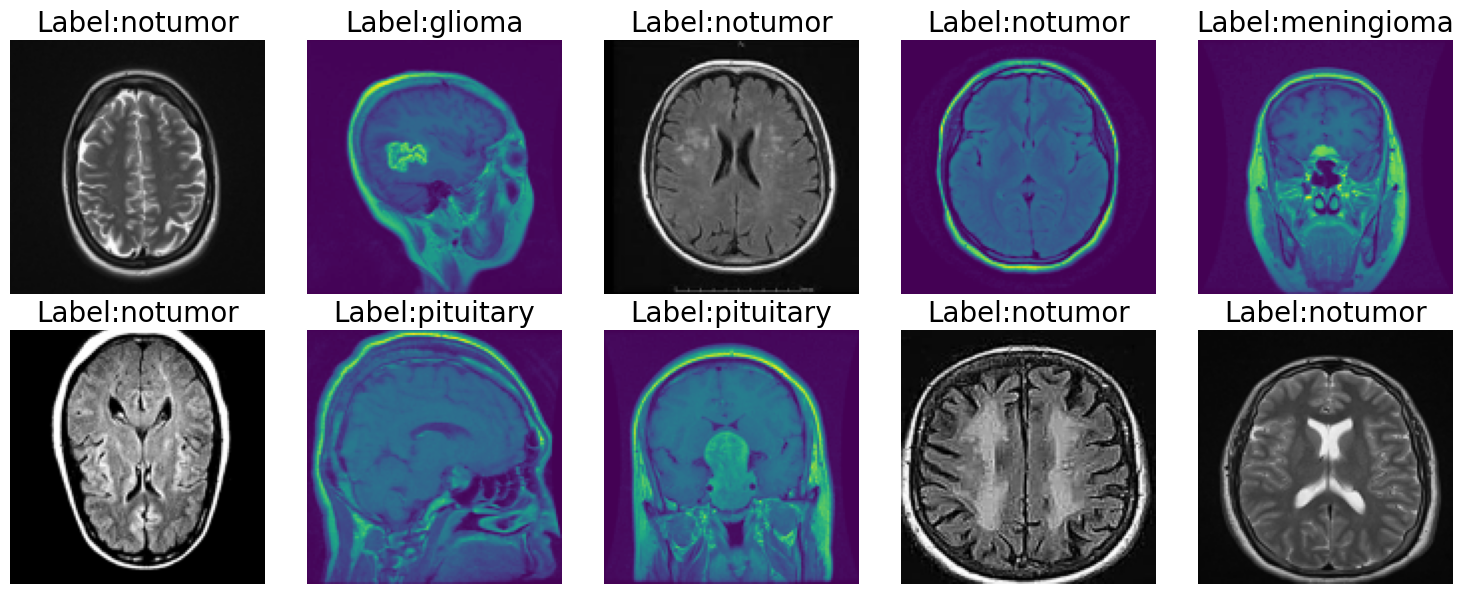

In [ ]:
import random
import matplotlib.pyplot as plt


random_indices = random.sample(range(len(train_paths)),10)



fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()


for i, index in enumerate(random_indices):
  img_path = train_paths[index]
  img = Image.open(img_path)
  img = img.resize((128, 128))
  axes[i].imshow(img)
  axes[i].axis('off')
  axes[i].set_title(f"Label:{train_labels[index]}", fontsize=20)


plt.tight_layout()
plt.show()


In [6]:
import os
import numpy as np
import random
from PIL import Image, ImageEnhance

# Define constants, also defined in mABrQxYOrv9b, for consistency in generator
IMAGE_SIZE = 128
train_dir = '/content/drive/MyDrive/MRI_Images/Training'

# Get class names for encoding labels
class_names = sorted(os.listdir(train_dir))
label_to_int = {name: i for i, name in enumerate(class_names)}

# Image Augmentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))  # Random brightness
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))  # Random contrast
    image = np.array(image) / 255.0  # Normalize pixel values to [0, 1]
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = augment_image(image)
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
def encode_label(labels):
    unique_labels = os.listdir(train_dir)  # Ensure unique labels are determined
    encoded = [unique_labels.index(label) for label in labels]
    return np.array(encoded)

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch


In [ ]:
import os
train_dir = '/content/drive/MyDrive/MRI_Images/Training'
len(os.listdir(train_dir))

['pituitary', 'meningioma', 'notumor', 'glioma']

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle
# Model architecture
IMAGE_SIZE = 128  # Image size (adjust based on your requirements)
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

# Freeze all layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set the last few layers of the VGG16 base model to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))  # Input layer
model.add(base_model)  # Add VGG16 base model
model.add(Flatten())  # Flatten the output of the base model
model.add(Dropout(0.3))  # Dropout layer for regularization
model.add(Dense(128, activation='relu'))  # Dense layer with ReLU activation
model.add(Dropout(0.2))  # Dropout layer for regularization
model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))  # Output layer with softmax activation

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

# Parameters
batch_size = 20
steps = int(len(train_paths) / batch_size)  # Steps per epoch
epochs = 5

# Train the model
history = model.fit(datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
                    epochs=epochs, steps_per_epoch=steps)

Epoch 1/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 1281s 5s/step - loss: 0.4612 - sparse_categorical_accuracy: 0.8259
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 899s 3s/step - loss: 0.2337 - sparse_categorical_accuracy: 0.9109
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 895s 3s/step - loss: 0.1541 - sparse_categorical_accuracy: 0.9436
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 890s 3s/step - loss: 0.1147 - sparse_categorical_accuracy: 0.9559
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 896s 3s/step - loss: 0.0856 - sparse_categorical_accuracy: 0.9692


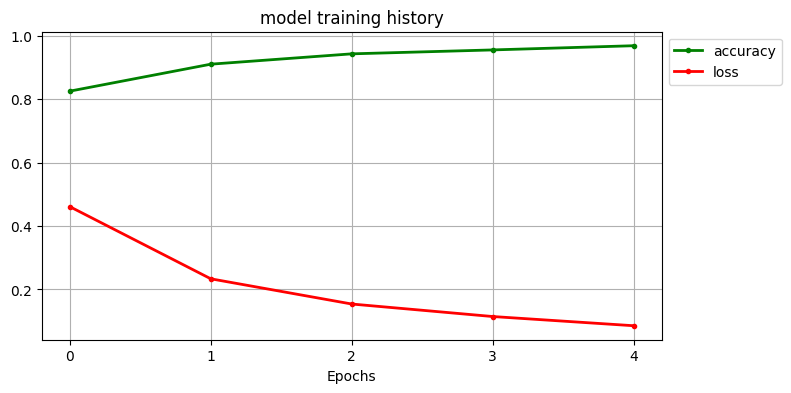

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'],'.g-', linewidth=2)
plt.plot(history.history['loss'],'.r-', linewidth=2)
plt.title('model training history')
plt.xlabel('Epochs')
plt.xticks([x for x in range(epochs)])

plt.legend(['accuracy','loss'], loc='upper left',bbox_to_anchor=(1,1))
plt.show()

In [19]:
import matplotlib.pyplot as plt
#from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
from sklearn.preprocessing import label_binarize
import numpy as np

# 1. Prediction on test data
test_images = open_images(test_paths)  # Load and augment test images
test_labels_encoded = encode_label(test_labels)  # Encode the test labels

# Predict using the trained model
test_predictions = model.predict(test_images)

# 2. Classification Report
print("Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1)))

50/50 ━━━━━━━━━━━━━━━━━━━━ 206s 4s/step
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       400
           1       0.81      0.95      0.87       400
           2       0.94      1.00      0.97       400
           3       0.97      0.72      0.83       400

    accuracy                           0.91      1600
   macro avg       0.92      0.91      0.91      1600
weighted avg       0.92      0.91      0.91      1600



Confusion Matrix:
[[393   5   2   0]
 [ 11 379   1   9]
 [  0   1 399   0]
 [  6  85  21 288]]


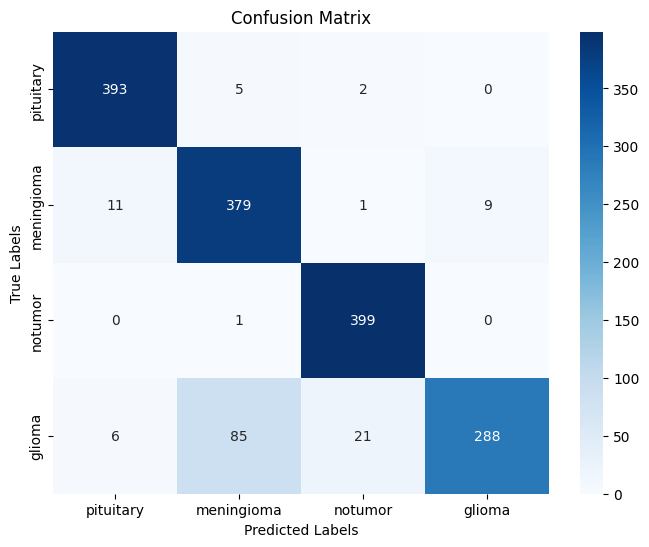

In [20]:
# 3. Confusion Matrix
conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(test_predictions, axis=1))
print("Confusion Matrix:")
print(conf_matrix)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=os.listdir(train_dir), yticklabels=os.listdir(train_dir))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [22]:
model.save('model.h5')

In [23]:
from tensorflow.keras.models import load_model
model = load_model('model.h5')

In [49]:
from keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Class labels - Corrected to match the encoding order during training (from os.listdir(train_dir))
# The order is: ['pituitary', 'meningioma', 'notumor', 'glioma']
class_labels = ['pituitary', 'meningioma', 'notumor', 'glioma']

def detect_and_display(img_path, model, image_size=128):
    """
    Function to detect tumor and display results.
    If no tumor is detected, it displays "No Tumor".
    Otherwise, it shows the predicted tumor class and confidence.
    """
    try:
        # Load and preprocess the image
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = img_to_array(img) / 255.0  # Normalize pixel values
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Make a prediction
        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]

        # Determine the class
        if class_labels[predicted_class_index] == 'notumor':
            result = "No Tumor"
        else:
            result = f"Tumor: {class_labels[predicted_class_index]}"

        # Display the image with the prediction
        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        # Removed plt.show() from here

    except Exception as e:
        print("Error processing the image:", str(e))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step


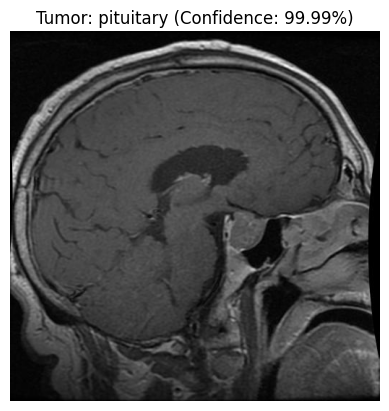

In [38]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/pituitary/Te-pi_112.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


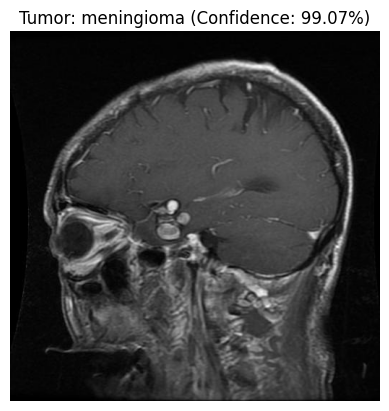

In [43]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/glioma/Te-gl_108.jpg'
detect_and_display(image_path, model)

Found a meningioma image misclassified as glioma: /content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-me_286.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step


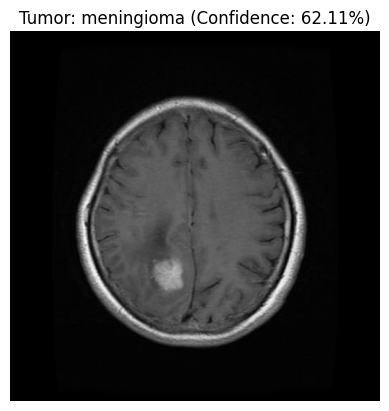

In [44]:
import numpy as np

# Find an image that is actually a meningioma (index 1) but predicted as glioma (index 3)
meningioma_as_glioma_indices = []
for i in range(len(test_labels_encoded)):
    if test_labels_encoded[i] == 1 and np.argmax(test_predictions, axis=1)[i] == 3:
        meningioma_as_glioma_indices.append(i)

if meningioma_as_glioma_indices:
    # Take the first such misclassified image
    misclassified_index = meningioma_as_glioma_indices[0]
    image_path_misclassified = test_paths[misclassified_index]
    print(f"Found a meningioma image misclassified as glioma: {image_path_misclassified}")
    detect_and_display(image_path_misclassified, model)
else:
    print("No meningioma images were misclassified as glioma in the test set.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step


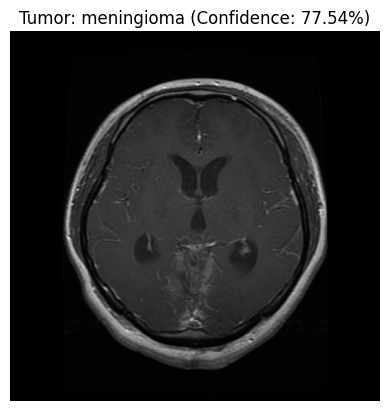

In [40]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/glioma/Te-gl_132.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step


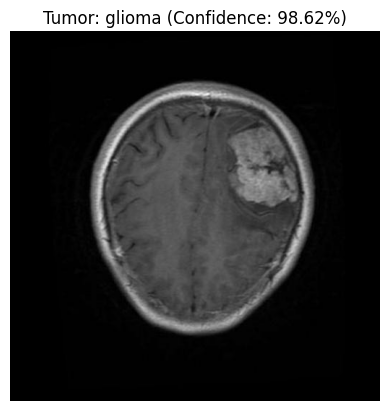

In [41]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-aug-me_2.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step


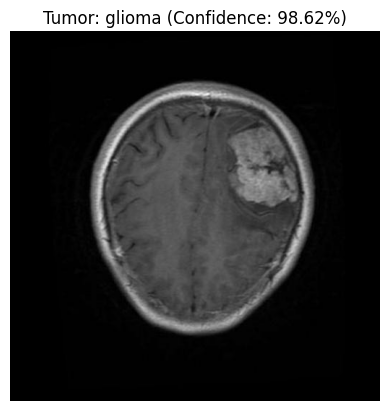

In [46]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-aug-me_2.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step


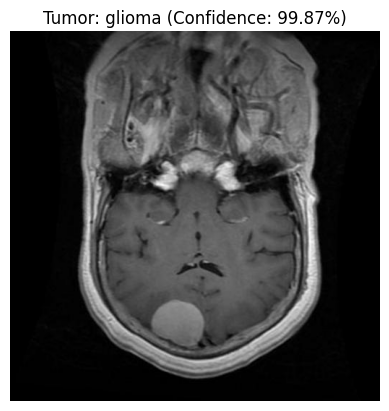

In [42]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-aug-me_30.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step


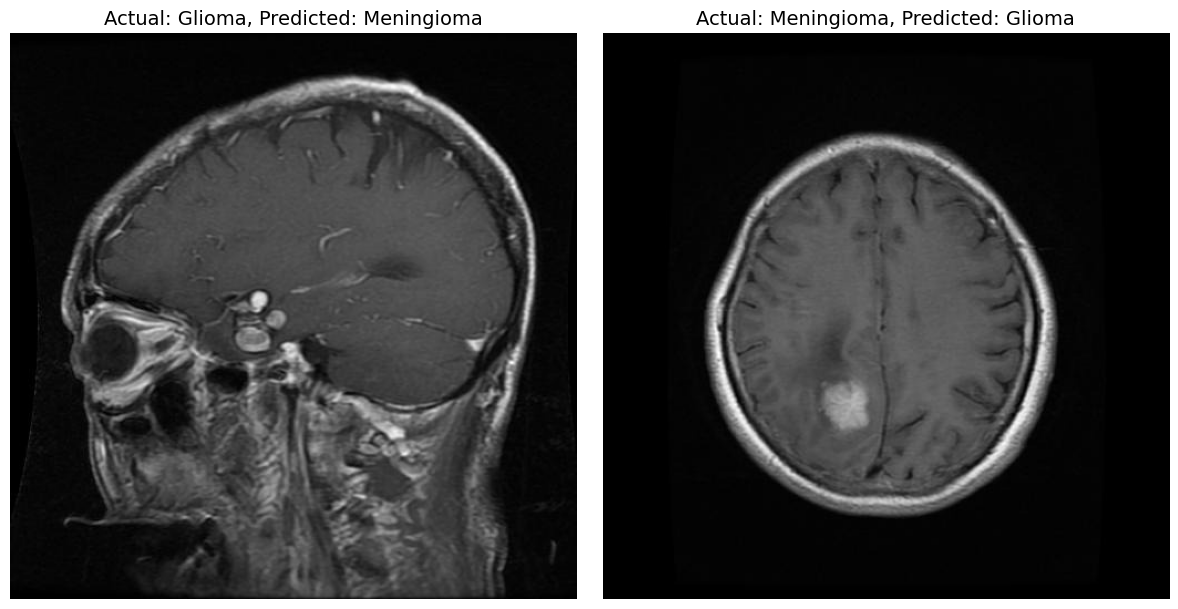

In [50]:
import matplotlib.pyplot as plt

# Image paths for the misclassified images
glioma_misclassified_as_meningioma_path = '/content/drive/MyDrive/MRI_Images/Testing/glioma/Te-gl_108.jpg'
meningioma_misclassified_as_glioma_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-me_286.jpg'

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
detect_and_display(glioma_misclassified_as_meningioma_path, model)
plt.title("Actual: Glioma, Predicted: Meningioma", fontsize=14)

plt.subplot(1, 2, 2)
detect_and_display(meningioma_misclassified_as_glioma_path, model)
plt.title("Actual: Meningioma, Predicted: Glioma", fontsize=14)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step


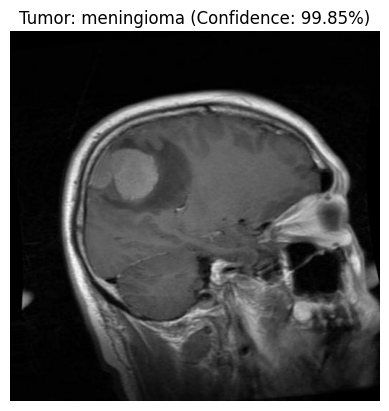

In [51]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-aug-me_33.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


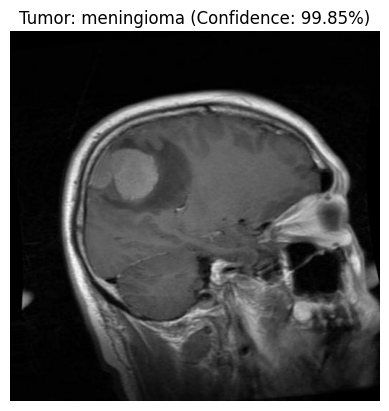

In [52]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-aug-me_33.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step


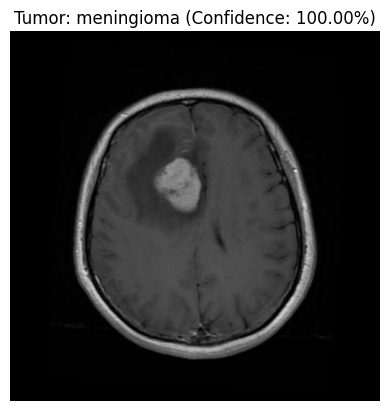

In [53]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-aug-me_57.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step


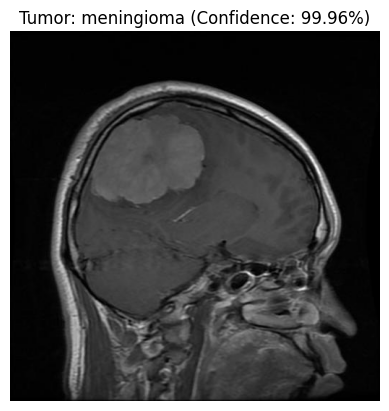

In [54]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/meningioma/Te-me_127.jpg'
detect_and_display(image_path, model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step


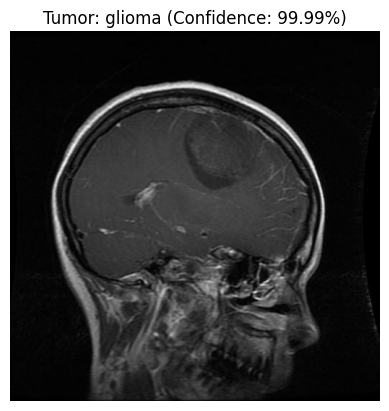

In [55]:
image_path = '/content/drive/MyDrive/MRI_Images/Testing/glioma/Te-gl_17.jpg'
detect_and_display(image_path, model)